In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('car_fuel_efficiency_2026.csv')

cols = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']
df = df[cols]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


np.float64(0.08080419601878173)

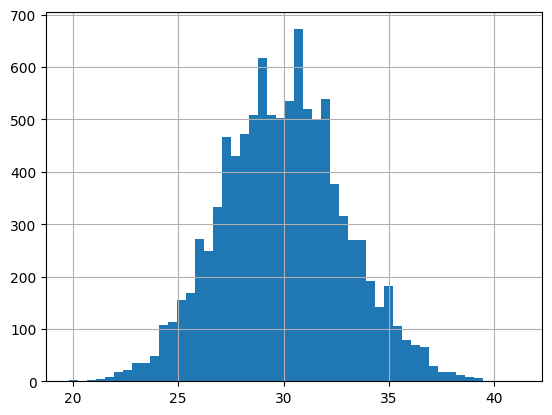

In [3]:
df['fuel_efficiency_mpg'].hist(bins=50)
# Check skew
df['fuel_efficiency_mpg'].skew()

In [4]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [5]:
df['horsepower'].median()

np.float64(254.0)

In [6]:
def split_data(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)

    return df_train, df_val, df_test

df_train, df_val, df_test = split_data(df, seed=42)

y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

df_train = df_train.drop(columns=['fuel_efficiency_mpg'])
df_val = df_val.drop(columns=['fuel_efficiency_mpg'])
df_test = df_test.drop(columns=['fuel_efficiency_mpg'])

len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [7]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T @ X
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv @ X.T @ y
    return w_full[0], w_full[1:]

def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T @ X
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv @ X.T @ y
    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [8]:
# Option 1: fill with 0
X_train_0 = df_train.fillna(0).values
X_val_0 = df_val.fillna(0).values

w0, w = train_linear_regression(X_train_0, y_train)
y_pred = w0 + X_val_0 @ w
rmse_0 = round(rmse(y_val, y_pred), 3)

# Option 2: fill with mean (computed on train only)
mean_hp = df_train['horsepower'].mean()

X_train_mean = df_train.fillna(mean_hp).values
X_val_mean = df_val.fillna(mean_hp).values

w0, w = train_linear_regression(X_train_mean, y_train)
y_pred = w0 + X_val_mean @ w
rmse_mean = round(rmse(y_val, y_pred), 3)

print('RMSE (fill 0):', rmse_0)
print('RMSE (fill mean):', rmse_mean)
print('Better option:', 'With 0' if rmse_0 < rmse_mean else ('With mean' if rmse_mean < rmse_0 else 'Both are equally good'))

RMSE (fill 0): 2.205
RMSE (fill mean): 2.202
Better option: With mean


In [9]:
X_train_0 = df_train.fillna(0).values
X_val_0 = df_val.fillna(0).values

results = {}
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train_0, y_train, r=r)
    y_pred = w0 + X_val_0 @ w
    score = round(rmse(y_val, y_pred), 4)
    results[r] = score
    print(f'r={r:<6} RMSE={score}')

best_r = min(results, key=lambda r: (results[r], r))
print('\nBest r:', best_r, 'RMSE:', results[best_r])

r=0      RMSE=2.2053
r=0.01   RMSE=2.2058
r=0.1    RMSE=2.2241
r=1      RMSE=2.3492
r=5      RMSE=2.4094
r=10     RMSE=2.4195
r=100    RMSE=2.4292

Best r: 0 RMSE: 2.2053


In [10]:
scores = []
for seed in range(10):
    df_train_s, df_val_s, df_test_s = split_data(df, seed=seed)

    y_train_s = df_train_s['fuel_efficiency_mpg'].values
    y_val_s = df_val_s['fuel_efficiency_mpg'].values

    X_train_s = df_train_s.drop(columns=['fuel_efficiency_mpg']).fillna(0).values
    X_val_s = df_val_s.drop(columns=['fuel_efficiency_mpg']).fillna(0).values

    w0, w = train_linear_regression(X_train_s, y_train_s)
    y_pred = w0 + X_val_s @ w
    score = rmse(y_val_s, y_pred)
    scores.append(score)

std = round(np.std(scores), 3)
print('Scores:', [round(s, 3) for s in scores])
print('Std:', std)

Scores: [np.float64(2.239), np.float64(2.202), np.float64(2.163), np.float64(2.204), np.float64(2.202), np.float64(2.246), np.float64(2.27), np.float64(2.191), np.float64(2.217), np.float64(2.207)]
Std: 0.029


In [11]:
df_train_9, df_val_9, df_test_9 = split_data(df, seed=9)

y_train_9 = df_train_9['fuel_efficiency_mpg'].values
y_val_9 = df_val_9['fuel_efficiency_mpg'].values
y_test_9 = df_test_9['fuel_efficiency_mpg'].values

df_full_train = pd.concat([df_train_9, df_val_9]).reset_index(drop=True)
y_full_train = np.concatenate([y_train_9, y_val_9])

X_full_train = df_full_train.drop(columns=['fuel_efficiency_mpg']).fillna(0).values
X_test_9 = df_test_9.drop(columns=['fuel_efficiency_mpg']).fillna(0).values

w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)
y_pred = w0 + X_test_9 @ w

test_rmse = round(rmse(y_test_9, y_pred), 3)
print('Test RMSE:', test_rmse)

Test RMSE: 2.236
